# Lab 2: Country Schools Dataset
## Data preprocessing, anomaly detection and cluster analysis

**Dataset:** `Country_Schools.csv` (47 counties, plus a TOTAL row and some blank rows)

**What I do in this notebook**
1. Data preprocessing (cleaning, type conversion, consistency checks, scaling)
2. Anomaly detection (Z-score, IQR, Isolation Forest, Local Outlier Factor)
3. Cluster analysis (K-Means with elbow and silhouette, hierarchical clustering, PCA visualisation)

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Load the data

In [2]:
# Works on Kaggle (/kaggle/input/...), locally, or when the CSV sits next to the notebook
candidates = glob.glob("/kaggle/input/**/Country_Schools.csv", recursive=True) + ["Country_Schools.csv", "/mnt/user-data/uploads/Country_Schools.csv"]
path = next(p for p in candidates if os.path.exists(p))
print("Reading:", path)

raw = pd.read_csv(path)
raw.head(10)

Reading: /mnt/user-data/uploads/Country_Schools.csv


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5
5,TAITA TAVETA,194.0,172.0,22.0,88.66%,6412.0,344.0,6
6,UASIN GISHU,456.0,353.0,103.0,77.41%,16024.0,706.0,7
7,MIGORI,601.0,413.0,188.0,68.72%,24453.0,826.0,8
8,VIHIGA,378.0,307.0,71.0,81.22%,18559.0,614.0,9
9,NYAMIRA,406.0,351.0,55.0,86.45%,14974.0,702.0,10


### Understanding the columns
| Column | Meaning |
|---|---|
| `SNO` | Name of the county (despite the column name, it is not a serial number) |
| `TOTALSCHOOLS` | Total number of schools in the county |
| `TotalSchoolsInstalled` | Schools where the devices have been installed |
| `SchoolsPending` | Schools still waiting (Total minus Installed) |
| `PercentageInstalled` | Installed / Total, stored as text like `10.34%` |
| `InstalledLDDs` | Number of learner devices installed |
| `InstalledTDDs` | Number of teacher devices installed |
| `FID` | Row id (no analytical meaning) |

## 2. Data preprocessing

### Step 1: Inspect shape, types, missing values and duplicates

In [3]:
print("Shape:", raw.shape)
print()
raw.info()
print()
print("Missing values per column:")
print(raw.isna().sum())
print()
print("Duplicate rows:", raw.duplicated().sum())

Shape: (50, 8)

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     str    
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     str    
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), str(2)
memory usage: 3.3 KB

Missing values per column:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

Duplicate rows: 0


In [4]:
# Look at the problem rows: the blank rows and the TOTAL row
raw.tail(5)

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


**Findings:** the file has 50 rows but only 47 are real counties.
- Two rows at the bottom are **completely blank** (only `FID` is filled).
- One row is called **TOTAL**. It is a summary of all the other rows, not a county. If we left it in, it would be a huge fake outlier (21,729 schools versus a typical county of a few hundred) and would ruin both the anomaly detection and the clustering.
- `PercentageInstalled` is stored as **text** (e.g. `"10.34%"`), so it must be converted to a number.
- County names have stray spaces (e.g. `"ElGEYO "`).

### Step 2: Remove blank rows and the TOTAL summary row

In [5]:
df = raw.copy()

# 1) drop rows where the county name is missing (the blank rows)
df = df.dropna(subset=["SNO"])

# 2) tidy the county names
df["SNO"] = df["SNO"].str.strip()

# 3) remove the TOTAL row (it is an aggregate, not an observation)
total_row = df[df["SNO"].str.upper() == "TOTAL"]
df = df[df["SNO"].str.upper() != "TOTAL"].copy()

print("Rows after cleaning:", len(df))
total_row

Rows after cleaning: 47


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48


### Step 3: Rename columns and fix data types

In [6]:
df = df.rename(columns={
    "SNO": "County",
    "TOTALSCHOOLS": "TotalSchools",
    "TotalSchoolsInstalled": "Installed",
    "SchoolsPending": "Pending",
    "PercentageInstalled": "PctInstalled",
    "InstalledLDDs": "LearnerDevices",
    "InstalledTDDs": "TeacherDevices",
})

# "10.34%" -> 10.34
df["PctInstalled"] = df["PctInstalled"].str.rstrip("%").astype(float)

# FID is just a row id, so drop it
df = df.drop(columns="FID").reset_index(drop=True)

# the numeric columns were floats only because of the blank rows, make them integers
for c in ["TotalSchools", "Installed", "Pending", "LearnerDevices", "TeacherDevices"]:
    df[c] = df[c].astype(int)

df.dtypes

County                str
TotalSchools        int64
Installed           int64
Pending             int64
PctInstalled      float64
LearnerDevices      int64
TeacherDevices      int64
dtype: object

### Step 4: Consistency checks (is the data trustworthy?)

In [7]:
# Installed + Pending should equal TotalSchools
print("Installed + Pending == TotalSchools for every county:",
      ((df.Installed + df.Pending) == df.TotalSchools).all())

# Percentage should equal Installed / Total * 100 (allowing rounding)
calc_pct = df.Installed / df.TotalSchools * 100
print("Max difference between stated % and calculated %:", round((calc_pct - df.PctInstalled).abs().max(), 4))

# Does the TOTAL row equal the sum of the counties?
print()
print("Sum of counties vs the original TOTAL row:")
print(pd.DataFrame({"sum_of_counties": df[["TotalSchools","Installed","Pending","LearnerDevices","TeacherDevices"]].sum(),
                    "TOTAL_row": total_row[["TOTALSCHOOLS","TotalSchoolsInstalled","SchoolsPending","InstalledLDDs","InstalledTDDs"]].iloc[0].values}))

# Teacher devices per installed school
print()
print("Teacher devices per installed school:")
print((df.TeacherDevices / df.Installed).describe().round(2))

Installed + Pending == TotalSchools for every county: True
Max difference between stated % and calculated %: 0.005

Sum of counties vs the original TOTAL row:
                sum_of_counties  TOTAL_row
TotalSchools              21729    21729.0
Installed                 14629    14629.0
Pending                    7100     7100.0
LearnerDevices           723618   723618.0
TeacherDevices            29258    29258.0

Teacher devices per installed school:
count    47.0
mean      2.0
std       0.0
min       2.0
25%       2.0
50%       2.0
75%       2.0
max       2.0
dtype: float64


**Findings**
- The numbers are internally consistent (Installed + Pending = Total, and the percentage matches the counts).
- The counties add up exactly to the TOTAL row, which confirms the TOTAL row is a pure summary and was correct to remove.
- `TeacherDevices` is **always exactly 2 x Installed schools**. It carries no extra information (it is perfectly correlated with `Installed`), so I will leave it out of the clustering features so that it does not count the same thing twice.

### Step 5: Summary statistics, distributions and correlations

In [8]:
num_cols = ["TotalSchools", "Installed", "Pending", "PctInstalled", "LearnerDevices", "TeacherDevices"]
df[num_cols].describe().round(2)

,TotalSchools,Installed,Pending,PctInstalled,LearnerDevices,TeacherDevices
count,47.00,47.00,47.00,47.00,47.00,47.00
mean,462.32,311.26,151.06,63.92,15396.13,622.51
std,254.20,229.00,113.80,25.85,11479.58,458.00
min,93.00,8.00,4.00,4.55,606.00,16.00
25%,251.50,156.50,52.50,50.30,6166.00,313.00
50%,413.00,307.00,130.00,65.00,13507.00,614.00
75%,633.50,408.50,243.00,84.94,22838.50,817.00
max,1238.00,1200.00,448.00,96.93,44338.00,2400.00


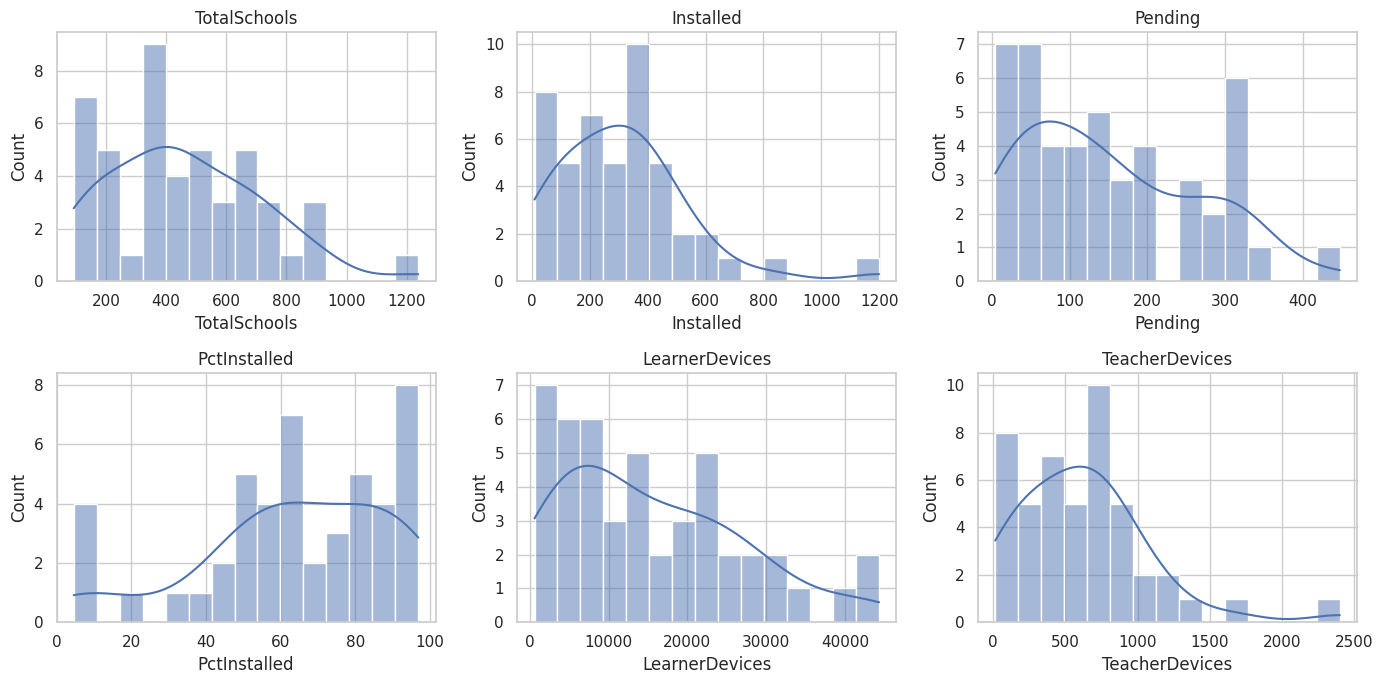

Skewness:
TotalSchools      0.66
Installed         1.43
Pending           0.64
PctInstalled     -0.80
LearnerDevices    0.75
TeacherDevices    1.43
dtype: float64


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=15, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

print("Skewness:")
print(df[num_cols].skew().round(2))

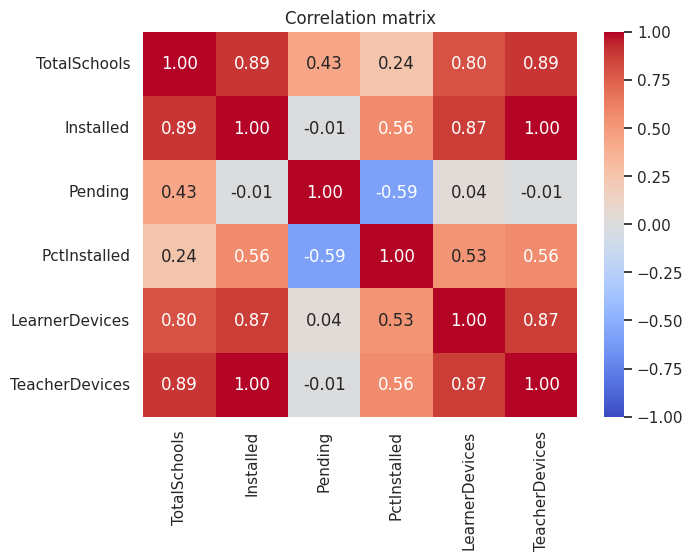

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### Step 6: Feature scaling

Anomaly detection and clustering both use distances between rows. `LearnerDevices` is in the tens of thousands while `PctInstalled` is between 0 and 100, so without scaling the big numbers would completely dominate. I standardise each feature (mean 0, standard deviation 1) with `StandardScaler`.

In [11]:
# Features for anomaly detection (teacher devices excluded: it is exactly 2 x Installed)
anom_features = ["TotalSchools", "Installed", "Pending", "PctInstalled", "LearnerDevices"]

scaler = StandardScaler()
X_anom = scaler.fit_transform(df[anom_features])
print("Scaled matrix shape:", X_anom.shape)
pd.DataFrame(X_anom, columns=anom_features).describe().round(2).loc[["mean", "std"]]

Scaled matrix shape: (47, 5)


,TotalSchools,Installed,Pending,PctInstalled,LearnerDevices
mean,-0.00,0.00,-0.00,0.00,0.00
std,1.01,1.01,1.01,1.01,1.01


## 3. Anomaly detection
An **anomaly** (outlier) is a record that behaves very differently from the rest. Here an anomaly is a county whose school or device numbers are unusual compared with the other counties. I use four different methods and compare them, because no single method is perfect.

### Method 1: Z-score
The Z-score says how many standard deviations a value is from the mean. A common rule is that `|z| > 3` is an outlier.

In [12]:
z = (df[anom_features] - df[anom_features].mean()) / df[anom_features].std()
z_flag = (z.abs() > 3).any(axis=1)

print("Counties flagged by Z-score (|z| > 3):")
display_cols = ["County"] + anom_features
df.loc[z_flag, display_cols].assign(max_abs_z=z.abs().max(axis=1)[z_flag].round(2))

Counties flagged by Z-score (|z| > 3):


,County,TotalSchools,Installed,Pending,PctInstalled,LearnerDevices,max_abs_z
3,KITUI,1238,1200,38,96.93,42162,3.88


### Method 2: IQR rule (boxplot rule)
A value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`, where IQR = Q3 - Q1. This is the same rule a boxplot uses to draw its dots.

TotalSchools    bounds = [   -321.5,    1206.5]  outliers: ['KITUI']
Installed       bounds = [   -221.5,     786.5]  outliers: ['KITUI', 'MAKUENI']
Pending         bounds = [   -233.2,     528.8]  outliers: []
PctInstalled    bounds = [     -1.6,     136.9]  outliers: []
LearnerDevices  bounds = [ -18842.8,   47847.2]  outliers: []


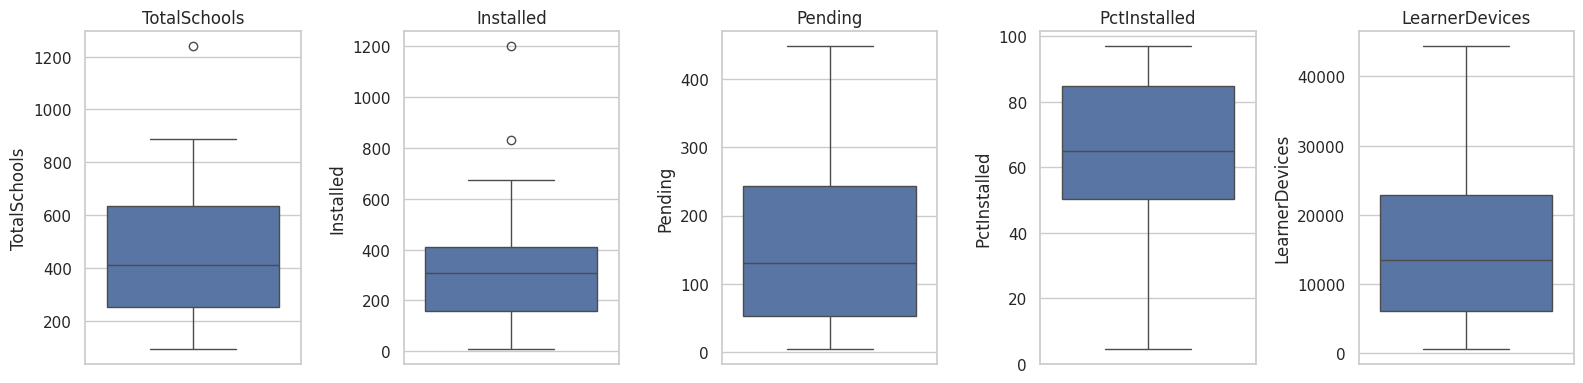

In [13]:
iqr_hits = {}
for c in anom_features:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    hits = df.loc[(df[c] < low) | (df[c] > high), "County"].tolist()
    iqr_hits[c] = hits
    print(f"{c:15s} bounds = [{low:9.1f}, {high:9.1f}]  outliers: {hits}")

iqr_flag = df["County"].isin(sum(iqr_hits.values(), []))

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, c in zip(axes, anom_features):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

### Method 3: Isolation Forest
Isolation Forest builds many random decision trees. Anomalies are different, so they are **isolated in fewer splits**. It looks at all features together, not one at a time. I assume about 10% of the 47 counties (around 5) could be unusual (`contamination=0.1`).

In [14]:
iso = IsolationForest(n_estimators=200, contamination=0.1, random_state=42)
iso.fit(X_anom)
df["iso_label"] = iso.predict(X_anom)               # -1 = anomaly, 1 = normal
df["iso_score"] = iso.decision_function(X_anom)     # lower = more anomalous
iso_flag = df["iso_label"] == -1

df.loc[iso_flag, ["County"] + anom_features + ["iso_score"]].sort_values("iso_score").round(3)

,County,TotalSchools,Installed,Pending,PctInstalled,LearnerDevices,iso_score
3,KITUI,1238,1200,38,96.93,42162,-0.153
17,KAKAMEGA,880,572,308,65.00,44338,-0.038
39,MACHAKOS,837,389,448,46.48,13369,-0.022
0,TURKANA,358,37,321,10.34,3744,-0.018
13,MAKUENI,887,833,54,93.91,30973,-0.018


### Method 4: Local Outlier Factor (LOF)
LOF compares how dense the neighbourhood of a point is with the density around its neighbours. A point in a much sparser area than its neighbours is a local outlier. With only 47 rows I use a small neighbourhood (`n_neighbors=5`).

In [15]:
lof = LocalOutlierFactor(n_neighbors=5, contamination=0.1)
df["lof_label"] = lof.fit_predict(X_anom)
df["lof_score"] = -lof.negative_outlier_factor_      # bigger = more anomalous
lof_flag = df["lof_label"] == -1

df.loc[lof_flag, ["County"] + anom_features + ["lof_score"]].sort_values("lof_score", ascending=False).round(3)

,County,TotalSchools,Installed,Pending,PctInstalled,LearnerDevices,lof_score
3,KITUI,1238,1200,38,96.93,42162,2.346
17,KAKAMEGA,880,572,308,65.00,44338,1.573
13,MAKUENI,887,833,54,93.91,30973,1.479
18,BUNGOMA,741,456,285,61.54,38744,1.295
46,SAMBURU,146,49,97,33.56,2891,1.231


### Comparing the four methods

In [16]:
votes = pd.DataFrame({
    "County": df["County"],
    "Z-score": z_flag.values,
    "IQR": iqr_flag.values,
    "IsolationForest": iso_flag.values,
    "LOF": lof_flag.values,
})
votes["n_methods"] = votes[["Z-score", "IQR", "IsolationForest", "LOF"]].sum(axis=1)
flagged = votes[votes.n_methods > 0].sort_values("n_methods", ascending=False)
flagged.merge(df[["County", "TotalSchools", "PctInstalled", "LearnerDevices"]], on="County")

,County,Z-score,IQR,IsolationForest,LOF,n_methods,TotalSchools,PctInstalled,LearnerDevices
0,KITUI,True,True,True,True,4,1238,96.93,42162
1,MAKUENI,False,True,True,True,3,887,93.91,30973
2,KAKAMEGA,False,False,True,True,2,880,65.00,44338
3,TURKANA,False,False,True,False,1,358,10.34,3744
4,BUNGOMA,False,False,False,True,1,741,61.54,38744
5,MACHAKOS,False,False,True,False,1,837,46.48,13369
6,SAMBURU,False,False,False,True,1,146,33.56,2891


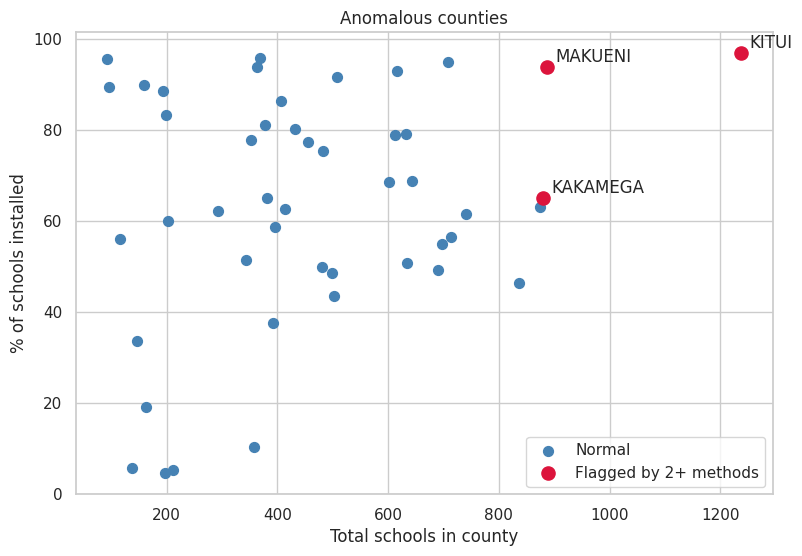

In [17]:
# Visual: all counties in two dimensions, anomalies highlighted
anomaly_counties = votes.loc[votes.n_methods >= 2, "County"]
is_anom = df["County"].isin(anomaly_counties)

plt.figure(figsize=(9, 6))
plt.scatter(df.loc[~is_anom, "TotalSchools"], df.loc[~is_anom, "PctInstalled"], c="steelblue", label="Normal", s=50)
plt.scatter(df.loc[is_anom, "TotalSchools"], df.loc[is_anom, "PctInstalled"], c="crimson", label="Flagged by 2+ methods", s=90)
for _, r in df[is_anom].iterrows():
    plt.annotate(r["County"], (r["TotalSchools"], r["PctInstalled"]), xytext=(6, 4), textcoords="offset points")
plt.xlabel("Total schools in county")
plt.ylabel("% of schools installed")
plt.title("Anomalous counties")
plt.legend()
plt.show()

### Interpretation of the anomaly detection results

**What the methods found**

| County | Methods that flagged it | Why it is unusual |
|---|---|---|
| **Kitui** | all 4 (Z-score, IQR, Isolation Forest, LOF) | The largest county in the data (1,238 schools) and almost fully installed (1,200 schools, 96.9%). Its Z-score is about 3.9, the only one above 3. |
| **Makueni** | 3 (IQR, Isolation Forest, LOF) | A very large county (887 schools) that is also almost fully installed (93.9%). Its installed count is above the IQR upper bound. |
| **Kakamega** | 2 (Isolation Forest, LOF) | The highest number of learner devices of any county (44,338), but only 65% of schools installed, so a large backlog remains (308 pending). |
| Turkana, Machakos, Bungoma, Samburu | 1 each | Flagged by only one method, so these are weak candidates. Turkana has very low coverage (10.3%), and Machakos has the largest backlog of pending schools (448). |

**How to read this**
- Kitui and Makueni are the strongest anomalies because several different methods agree. They are not data errors: the numbers are internally consistent (Installed + Pending = Total). They are simply the biggest counties with the highest coverage, so they sit at the far end of the distribution.
- Kakamega shows up only in the multivariate methods (Isolation Forest and LOF), not in Z-score or IQR. No single value is extreme, but the **combination** (many schools, very many devices, middling coverage) is unusual. This is why using more than one method matters.
- Z-score and IQR look at one column at a time, so they only catch extreme values. Isolation Forest and LOF look at all columns together, so they catch unusual combinations. Because I set `contamination=0.1`, Isolation Forest and LOF will always flag about 5 counties whether or not they are truly extreme, so a county flagged by only one of them should be treated with caution.
- Anomalies are not necessarily problems. Here they point to counties worth a closer look: the very large high-coverage counties, and the counties with a big backlog.

## 4. Cluster analysis
**Clustering** groups counties that look alike, without any labels telling us what the groups should be (unsupervised learning). The goal is to find natural groups of counties, for example "large and well covered" versus "small and lagging".

**Feature choice**
- `TotalSchools` (size of the county)
- `Pending` (how much work is left)
- `PctInstalled` (how well covered it is)

The count features are strongly right-skewed (a few big counties), so I apply a `log1p` transform to them before scaling. I leave out `Installed`, `LearnerDevices` and `TeacherDevices` because they are almost entirely determined by the county size and coverage already (the correlation matrix above shows correlations of 0.8 and higher), so they would count the same information several times.

In [18]:
cluster_features = ["TotalSchools", "Pending", "PctInstalled"]

X_raw = np.column_stack([
    np.log1p(df["TotalSchools"]),
    np.log1p(df["Pending"]),
    df["PctInstalled"],
])
X_clu = StandardScaler().fit_transform(X_raw)
X_clu.shape

(47, 3)

### Choosing the number of clusters (k): elbow method and silhouette score

- **Elbow method:** plot the inertia (within-cluster sum of squares) for different k. Look for the bend where adding clusters stops helping much.
- **Silhouette score:** between -1 and 1. Higher means clusters are tight and well separated.

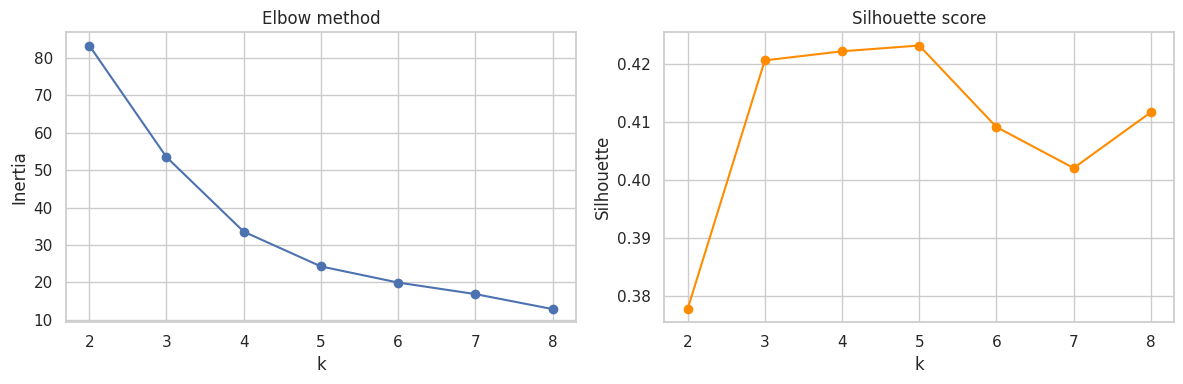

,k,inertia,silhouette
0,2,83.29,0.378
1,3,53.47,0.421
2,4,33.56,0.422
3,5,24.27,0.423
4,6,19.96,0.409
5,7,16.88,0.402
6,8,12.88,0.412


In [19]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_clu, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker="o")
ax[0].set_title("Elbow method")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(ks), sils, marker="o", color="darkorange")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(ks), "inertia": np.round(inertias, 2), "silhouette": np.round(sils, 3)})

**Choosing k.** The silhouette score is almost the same for k = 3, 4 and 5 (about 0.42) and gets worse after that, and the inertia curve bends at about k = 3 to 4. I choose **k = 4**: the silhouette is as good as k = 3, and four groups are easier to interpret in a meaningful way (see the profiles below).

### K-Means with k = 4

In [20]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X_clu)

print("Silhouette score for k=4:", round(silhouette_score(X_clu, df["cluster"]), 3))
print()
print("Counties per cluster:")
print(df["cluster"].value_counts().sort_index())

Silhouette score for k=4: 0.422

Counties per cluster:
cluster
0     9
1    19
2     6
3    13
Name: count, dtype: int64


### Cluster profiles (what makes each group different?)

In [21]:
profile = df.groupby("cluster")[["TotalSchools", "Pending", "PctInstalled", "LearnerDevices"]].mean().round(1)
profile["n_counties"] = df["cluster"].value_counts().sort_index()
profile

,TotalSchools,Pending,PctInstalled,LearnerDevices,n_counties
cluster,,,,,
0,199.2,28.2,83.7,8445.2,9
1,579.7,252.3,56.0,16275.2,19
2,202.3,178.2,13.1,1785.2,6
3,592.9,75.6,85.2,25205.5,13


In [22]:
for c in sorted(df["cluster"].unique()):
    print(f"Cluster {c}: {', '.join(df.loc[df.cluster == c, 'County'])}")
    print()

Cluster 0: TANA RIVER, TAITA TAVETA, MOMBASA, LAMU, ElGEYO, KWALE, KIRINYAGA, ISIOLO, NAIROBI

Cluster 1: HOMA BAY, WEST POKOT, MIGORI, KISII, KAKAMEGA, BUNGOMA, SIAYA, KERICHO, MERU, LAIKIPIA, KIAMBU, NYERI, NYANDARUA, MACHAKOS, NAKURU, THARAKA NITHI, BARINGO, KAJIADO, EMBU

Cluster 2: TURKANA, GARISSA, MANDERA, WAJIR, MARSABIT, SAMBURU

Cluster 3: KITUI, UASIN GISHU, VIHIGA, NYAMIRA, NAROK, NANDI, MAKUENI, KISUMU, BOMET, KILIFI, BUSIA, TRANS NZOIA, MURANG'A



### Visualising the clusters with PCA

The data has three dimensions, so PCA squeezes it into two so we can plot it. The axes are combinations of the original features, and the plot shows whether the groups are separated.

Variance explained by PC1 and PC2: [0.58  0.401] -> total 0.981


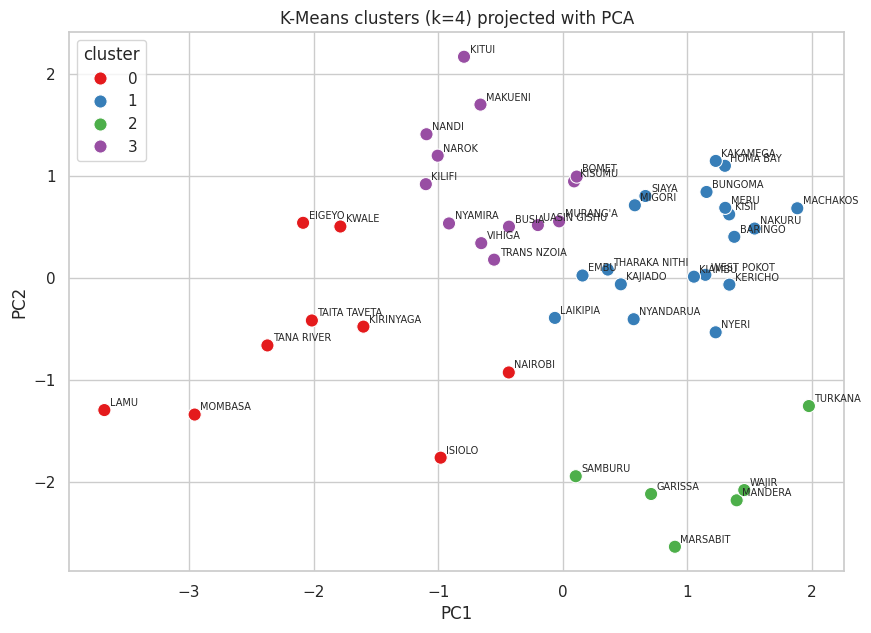

In [23]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_clu)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3), "-> total", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(10, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["cluster"], palette="Set1", s=90)
for i, name in enumerate(df["County"]):
    plt.annotate(name, (coords[i, 0], coords[i, 1]), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("K-Means clusters (k=4) projected with PCA")
plt.show()

### Hierarchical clustering (to cross-check K-Means)

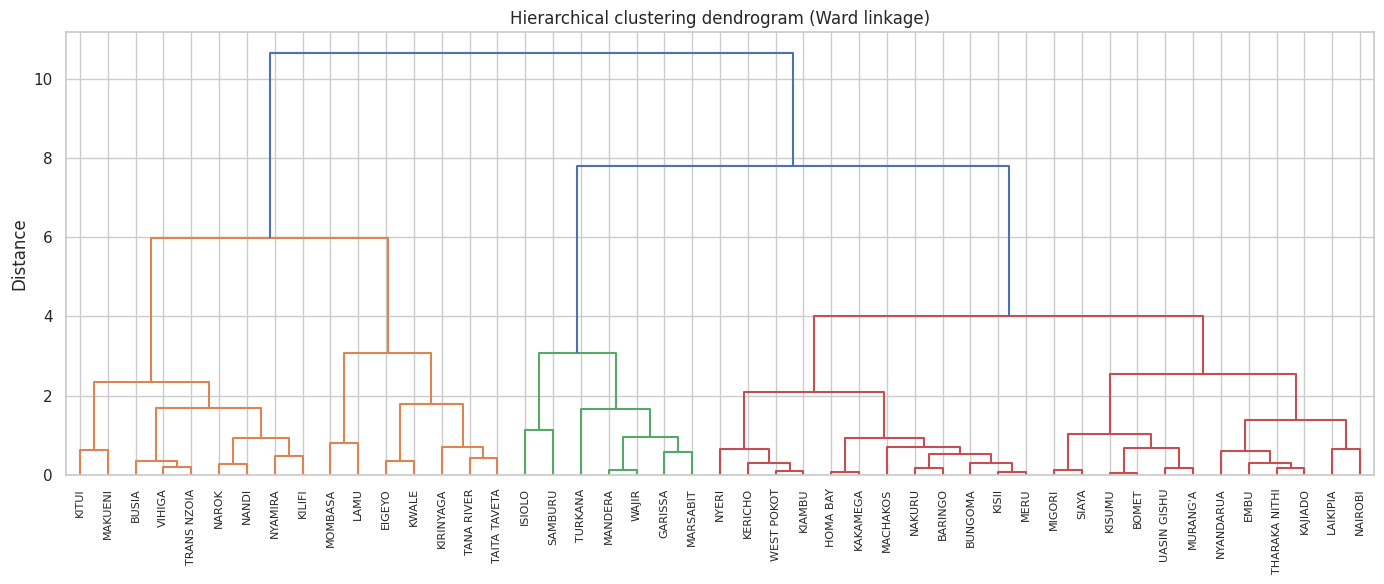

Silhouette score (hierarchical, k=4): 0.394

Agreement between K-Means and hierarchical clusters (rows = K-Means, columns = hierarchical):


hier_cluster,0,1,2,3
cluster,,,,
0,1,7,1,0
1,19,0,0,0
2,0,0,6,0
3,4,0,0,9


In [24]:
Z = linkage(X_clu, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=df["County"].values, leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical clustering dendrogram (Ward linkage)")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

hier = AgglomerativeClustering(n_clusters=4, linkage="ward")
df["hier_cluster"] = hier.fit_predict(X_clu)
print("Silhouette score (hierarchical, k=4):", round(silhouette_score(X_clu, df["hier_cluster"]), 3))
print()
print("Agreement between K-Means and hierarchical clusters (rows = K-Means, columns = hierarchical):")
pd.crosstab(df["cluster"], df["hier_cluster"])

### Interpretation of the cluster analysis results

**Choosing k and cluster quality**
- The silhouette score is about 0.42 for k = 3, 4 and 5, so it is almost flat there and falls for larger k. A score of about 0.4 means the structure is real but moderate, not perfectly separated. I used k = 4 because it gives groups that are easy to explain.
- PCA captured about 98% of the variance in just two components, so the 2D plot is a faithful picture of the data.

**The four clusters**

| Cluster | Counties | Profile |
|---|---|---|
| **0: Small and nearly done** | 9 (e.g. Nairobi, Mombasa, Lamu, Tana River, Taita Taveta, Kwale) | Small counties (about 199 schools on average), already about 84% installed with only about 28 schools pending. |
| **1: Medium-large with the biggest backlog** | 19 (e.g. Homa Bay, Kakamega, Bungoma, Nakuru, Kiambu, Machakos) | About 580 schools each, only about 56% installed and the most pending schools (about 252). The largest group, so most of the remaining work is here. |
| **2: Small and far behind** | 6 (Turkana, Garissa, Mandera, Wajir, Marsabit, Samburu) | Small counties (about 202 schools) with very low coverage (about 13% installed). These are the clear laggards. |
| **3: Large and well covered** | 13 (e.g. Kitui, Makueni, Uasin Gishu, Kisumu, Narok, Kilifi) | About 593 schools, about 85% installed, few pending (about 76) and the most devices on average (about 25,000 learner devices). |

**Interpretation**
- The clusters split on two things: county **size** (small versus large) and **progress** (how much is installed).
- Cluster 2 is the most important finding. Its counties are clearly separated from every other group by coverage, not by size. They are all counties in northern Kenya. The data cannot tell us why they lag behind (remoteness, power supply, security and logistics are possible explanations, but that would need other data to confirm).
- Clusters 0 and 2 are similar in size but opposite in progress, which shows that county size alone does not explain coverage.
- Hierarchical clustering gives the same picture: clusters 1 and 2 match exactly (19 of 19 and 6 of 6 counties), and the differences are only for a few borderline counties between clusters 0 and 3. K-Means has the slightly better silhouette (0.422 versus 0.394), so I keep the K-Means result.

## 5. Linking the two analyses
Checking whether the anomalous counties belong to a particular cluster tells us if they are genuinely odd or just the extreme edge of a group.

In [25]:
df["n_anomaly_methods"] = votes["n_methods"].values
df.loc[df["n_anomaly_methods"] >= 2, ["County", "TotalSchools", "PctInstalled", "n_anomaly_methods", "cluster"]].sort_values("n_anomaly_methods", ascending=False)

,County,TotalSchools,PctInstalled,n_anomaly_methods,cluster
3,KITUI,1238,96.93,4,3
13,MAKUENI,887,93.91,3,3
17,KAKAMEGA,880,65.00,2,1


## 6. Conclusion

- **Preprocessing mattered a lot.** The raw file had two blank rows, a TOTAL summary row, a percentage stored as text, messy county names, and a redundant column (`InstalledTDDs` is always exactly 2 x installed schools). Without removing the TOTAL row, it would have been flagged as the biggest anomaly and would have distorted the clusters.
- **Anomaly detection:** Kitui is the clearest anomaly (flagged by all four methods), followed by Makueni (three methods) and Kakamega (two methods, because of its unusual combination of values). These are genuine extreme counties, not errors.
- **Cluster analysis:** the 47 counties fall into four groups: small and nearly done, medium-large with the biggest backlog, small and far behind, and large and well covered. The six counties in the "far behind" group stand out most, with only about 13% installed.
- **Limitations:** with only 47 rows the results are sensitive to settings such as `contamination` and `k`, and the silhouette of about 0.42 shows moderate rather than sharp clusters. The data covers one snapshot and has no information about why some counties are behind.